In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("../data/ecommerce_sales_analytics_5000.csv")            #Load your dataset

In [8]:
df.head()                           #Display first five records

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [9]:
df.shape                     #Check dataset dimensions

(5000, 12)

In [10]:
df.info()                    #Check column information

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   str    
 4   region            5000 non-null   str    
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   str    
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), str(4)
memory usage: 468.9 KB


In [11]:
df.describe()                    #Statistical summary

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [12]:
df.isnull().sum()                  #Check missing values    

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [13]:
df.duplicated().sum()                   #Check duplicate records

np.int64(0)

In [14]:
for col in df.columns:                                 #Check unique values
    print(col, ":",df[col].nunique())

order_id : 5000
order_date : 5000
customer_id : 989
product_category : 4
region : 4
quantity : 7
unit_price : 4788
discount : 36
payment_method : 3
delivery_days : 11
customer_rating : 41
revenue : 4940


In [15]:
df['order_date'] = pd.to_datetime(df['order_date'])          #Convert order_date into datetime

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          5000 non-null   int64         
 1   order_date        5000 non-null   datetime64[us]
 2   customer_id       5000 non-null   int64         
 3   product_category  5000 non-null   str           
 4   region            5000 non-null   str           
 5   quantity          5000 non-null   int64         
 6   unit_price        5000 non-null   float64       
 7   discount          5000 non-null   float64       
 8   payment_method    5000 non-null   str           
 9   delivery_days     5000 non-null   int64         
 10  customer_rating   5000 non-null   float64       
 11  revenue           5000 non-null   float64       
dtypes: datetime64[us](1), float64(4), int64(4), str(3)
memory usage: 468.9 KB


In [18]:
print("Product Categories:")                     #Check categorical values
print(df['product_category'].unique())

print("\nRegions:")
print(df['region'].unique())

print("\nPayment Methods:")
print(df['payment_method'].unique())

Product Categories:
<StringArray>
['Beauty', 'Clothing', 'Electronics', 'Home']
Length: 4, dtype: str

Regions:
<StringArray>
['South', 'East', 'West', 'North']
Length: 4, dtype: str

Payment Methods:
<StringArray>
['Wallet', 'Card', 'COD']
Length: 3, dtype: str


In [19]:
df[['quantity','unit_price','discount','delivery_days','customer_rating','revenue']].describe()                #Check numerical columns

,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [25]:
total_revenue = df['revenue'].sum()                      #Exploratory Data Analysis (EDA)
total_orders = df['order_id'].nunique()                  #Pandas for data analysis.  
total_customers = df['customer_id'].nunique()            #NumPy for numerical calculations.
total_quantity = df['quantity'].sum()                    #Matplotlib and Seaborn for visualization.
average_order_value = df['revenue'].mean()
average_rating = df['customer_rating'].mean()            #These are called Key Performance Indicators (KPIs).

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products Sold:", total_quantity)
print("Average Order Value:", average_order_value)
print("Average Customer Rating:", average_rating)

Total Revenue: 5109775.74
Total Orders: 5000
Total Customers: 989
Total Products Sold: 20224
Average Order Value: 1021.955148
Average Customer Rating: 2.9739800000000005


In [26]:
region_revenue = df.groupby('region')['revenue'].sum()             #Analyse regional sales
region_revenue = region_revenue.sort_values(ascending=False)
print(region_revenue)

region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64


In [27]:
payment_analysis = df['payment_method'].value_counts()     #Analyse payment methods
print(payment_analysis)

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64


In [29]:
df['month'] = df['order_date'].dt.month             #Analyse monthly revenue
df['year'] = df['order_date'].dt.year

In [30]:
monthly_revenue = df.groupby('month')['revenue'].sum()
print(monthly_revenue)

month
1     426374.92
2     413890.24
3     425050.52
4     398715.16
5     479772.55
6     442941.58
7     440570.72
8     460874.78
9     402368.11
10    407873.12
11    410657.88
12    400686.16
Name: revenue, dtype: float64


In [31]:
rating_analysis = df.groupby('product_category')['customer_rating'].mean()  #Analyse customer ratings
print(rating_analysis)

product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64


In [32]:
print("Total Revenue:", np.sum(df['revenue']))       #Calculate total and average revenue    
print("Average Revenue:", np.mean(df['revenue']))
print("Maximum Revenue:", np.max(df['revenue']))
print("Minimum Revenue:", np.min(df['revenue']))
print("Median Revenue:", np.median(df['revenue']))

Total Revenue: 5109775.74
Average Revenue: 1021.955148
Maximum Revenue: 4119.33
Minimum Revenue: 11.21
Median Revenue: 796.65


In [33]:
category_stats = df.groupby('product_category')['revenue'].agg(
    ['sum', 'mean', 'max', 'min', 'count']               #Calculate revenue by product category
)
print(category_stats)

                         sum         mean      max    min  count
product_category                                                
Beauty             765860.88  1059.281992  4005.93  20.94    723
Clothing          1531931.72  1000.608570  3928.63  11.21   1531
Electronics       1829899.22  1029.768835  4119.33  13.26   1777
Home               982083.92  1013.502497  3640.56  13.01    969


In [34]:
discount_analysis = df.groupby('product_category')['discount'].mean()        #Calculate discount impact
print(discount_analysis)

product_category
Beauty         0.181425
Clothing       0.184259
Electronics    0.176652
Home           0.178266
Name: discount, dtype: float64


In [35]:
delivery_analysis = df.groupby('region')['delivery_days'].mean()      #Analyse delivery performance
print(delivery_analysis.sort_values())

region
West     6.082234
East     6.104319
North    6.118339
South    6.173013
Name: delivery_days, dtype: float64


In [36]:
top_customers = (                            #Identify top 10 customers
    df.groupby('customer_id')['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers)

customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64


In [37]:
customer_analysis = df.groupby('customer_id').agg(              #Analyse customer purchasing behaviour
    total_orders=('order_id', 'nunique'),
    total_spending=('revenue', 'sum'),
    average_spending=('revenue', 'mean')
)

print(customer_analysis.head(10))

             total_orders  total_spending  average_spending
customer_id                                                
1000                    9         6905.58        767.286667
1001                    6         3959.74        659.956667
1002                    4         1579.67        394.917500
1003                    2         2304.44       1152.220000
1004                    5         6073.85       1214.770000
1005                    1         1064.95       1064.950000
1006                    7         4970.23        710.032857
1007                    7         3919.88        559.982857
1008                    3         3078.46       1026.153333
1009                    6         5177.07        862.845000


In [40]:
#Data Visualization 📊

In [41]:
category_revenue = df.groupby('product_category')['revenue'].sum()

category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64


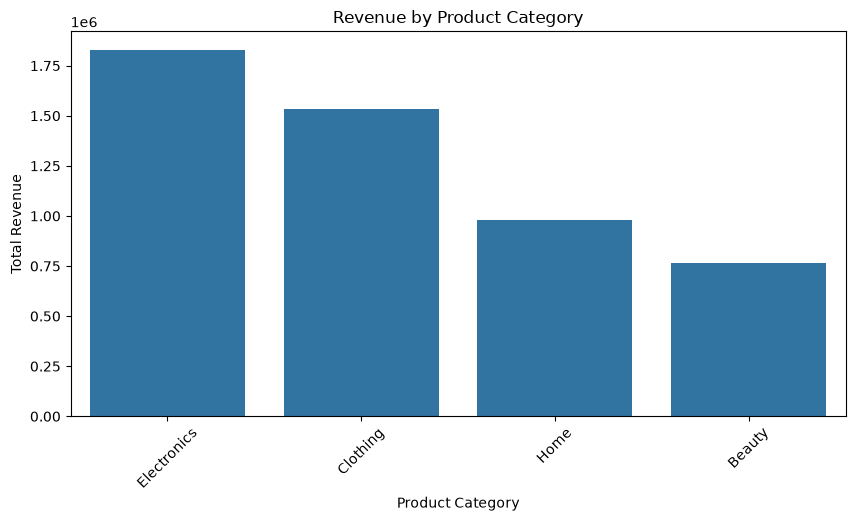

In [42]:
plt.figure(figsize=(10, 5))               #Revenue by Product Category (Bar Chart)
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

In [43]:
df['year_month'] = df['order_date'].dt.to_period('M')           #Monthly Revenue Trend (Line Chart)
monthly_sales = df.groupby('year_month')['revenue'].sum()
monthly_sales.index = monthly_sales.index.astype(str)

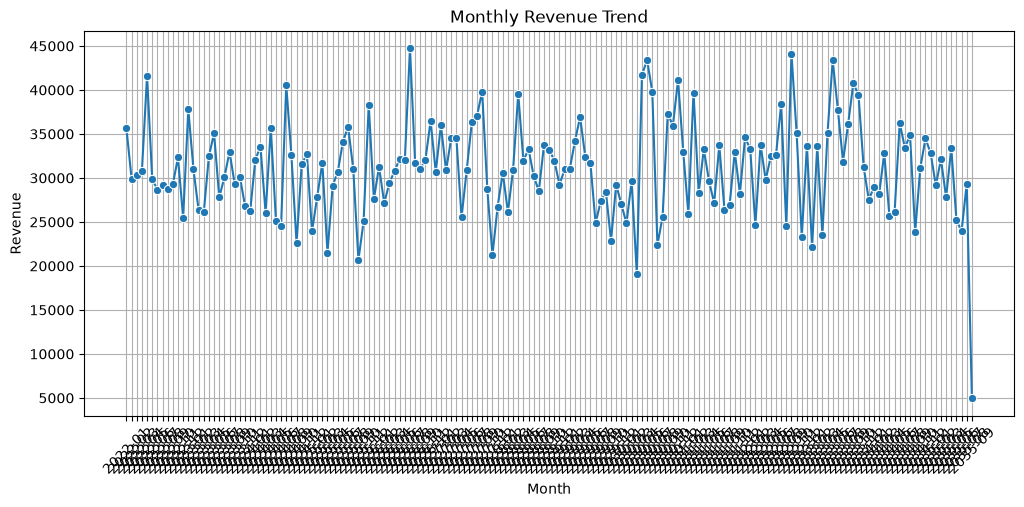

In [44]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker='o'
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.grid()
plt.show()

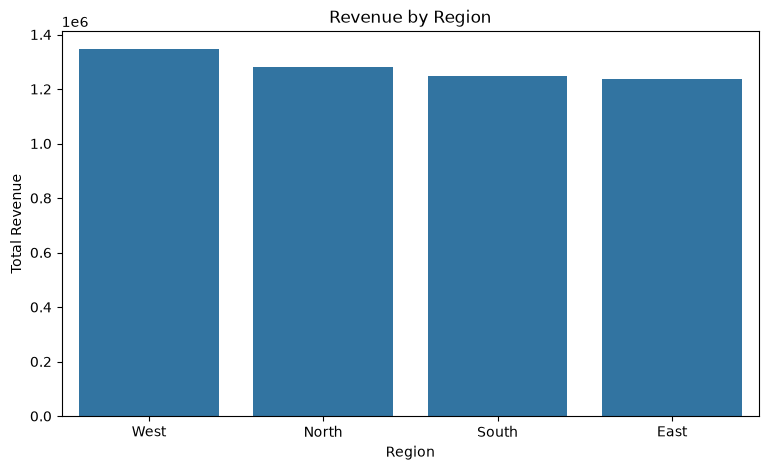

In [45]:
plt.figure(figsize=(9, 5))          #Regional Revenue (Bar Chart)

sns.barplot(
    x=region_revenue.index,
    y=region_revenue.values
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")

plt.show()

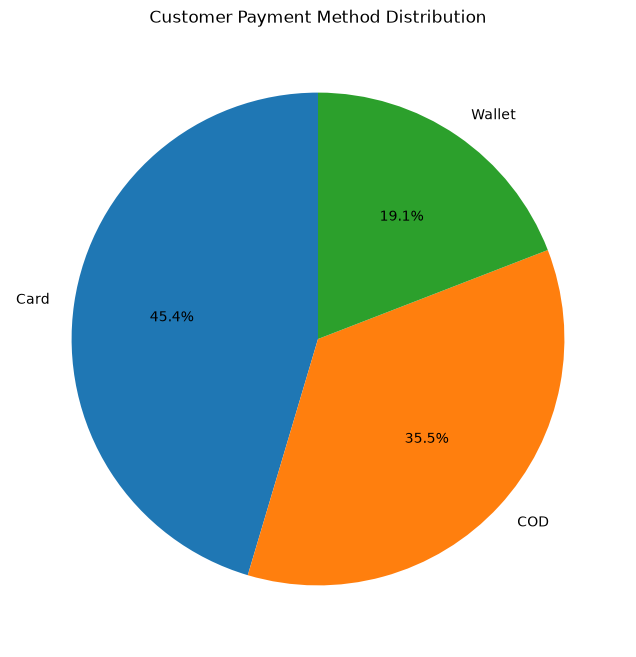

In [46]:
payment_counts = df['payment_method'].value_counts()           #Payment Method Distribution (Pie Chart)

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Customer Payment Method Distribution")

plt.show()

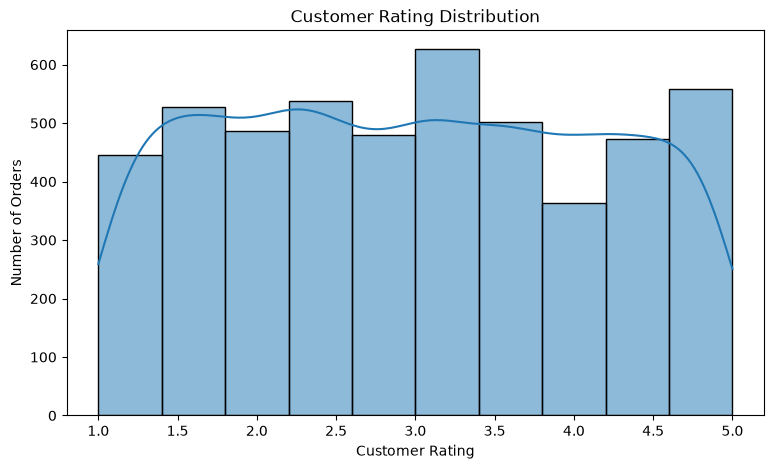

In [47]:
plt.figure(figsize=(9, 5))                #Customer Rating Distribution (Histogram)

sns.histplot(
    df['customer_rating'],
    bins=10,
    kde=True
)

plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Orders")

plt.show()

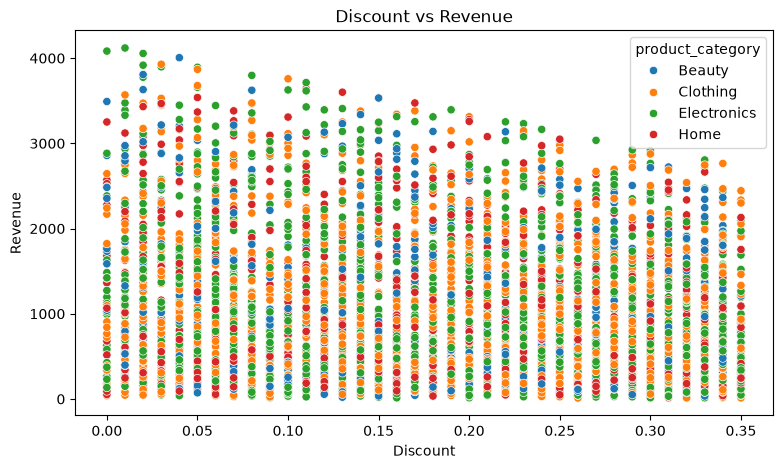

In [48]:
plt.figure(figsize=(9, 5))               #Discount vs Revenue (Scatter Plot)

sns.scatterplot(
    data=df,
    x='discount',
    y='revenue',
    hue='product_category'
)

plt.title("Discount vs Revenue")
plt.xlabel("Discount")
plt.ylabel("Revenue")

plt.show()

In [ ]:
df.to_csv('../data/ecommerce_cleaned.csv', index=False)